# Exercice 5 — Sous-graphiques et mise en page

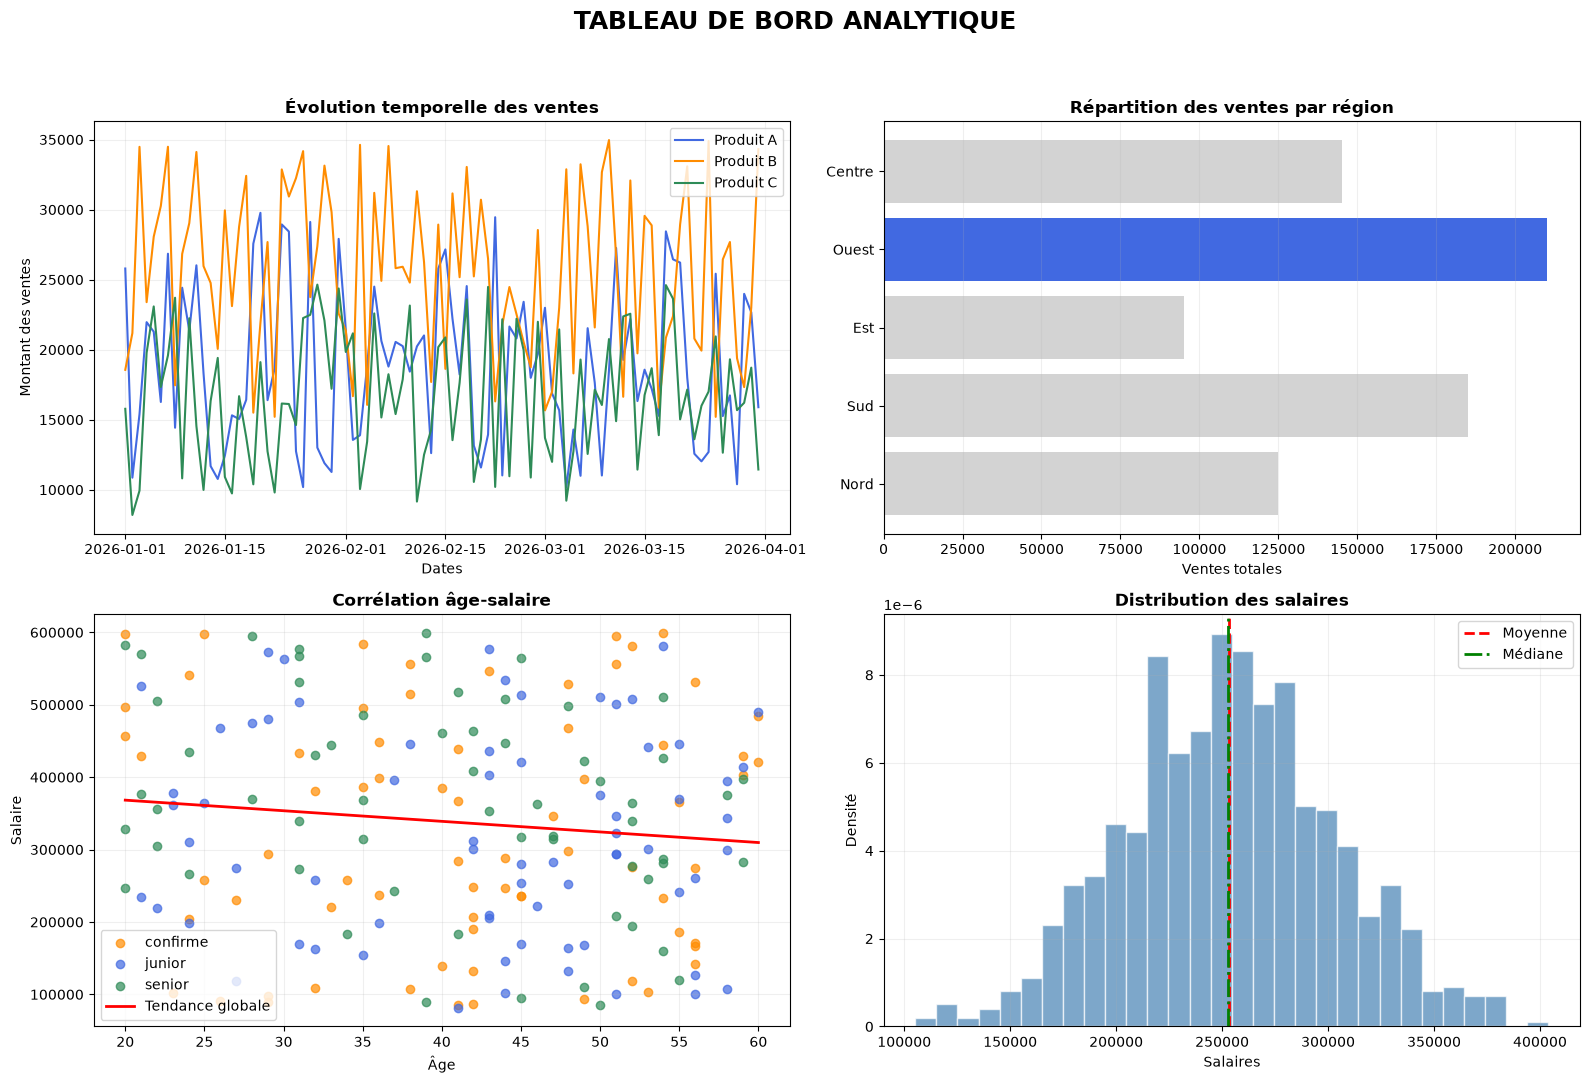

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==================================
# 1. GÉNÉRATION DES DONNÉES
# ==================================

np.random.seed(42)

# Ventes journalières sur 90 jours
dates = pd.date_range(start="2026-01-01", periods=90)

ventes = pd.DataFrame({
    "date": dates,
    "Produit A": np.random.randint(10000, 30000, 90),
    "Produit B": np.random.randint(15000, 35000, 90),
    "Produit C": np.random.randint(8000, 25000, 90)
})

# Ventes par région
regions = pd.DataFrame({
    "region": ["Nord", "Sud", "Est", "Ouest", "Centre"],
    "ventes_totales": [125000, 185000, 95000, 210000, 145000]
})

# Données de 200 individus
individus = pd.DataFrame({
    "age": np.random.randint(20, 61, 200),
    "salaire": np.random.randint(80000, 600000, 200),
    "categorie": np.random.choice(
        ["junior", "confirme", "senior"],
        200
    )
})

# Distribution de 1000 salaires
salaires = pd.DataFrame({
    "salaire": np.random.normal(250000, 50000, 1000)
})


# ==================================
# 2. CRÉATION DE LA FIGURE
# ==================================

fig, ax = plt.subplots(2, 2, figsize=(16, 11))

fig.suptitle(
    "TABLEAU DE BORD ANALYTIQUE",
    fontsize=18,
    fontweight="bold"
)

# ==================================
# GRAPHIQUE 1 : ÉVOLUTION TEMPORELLE
# ==================================

ax[0, 0].plot(
    ventes["date"],
    ventes["Produit A"],
    label="Produit A",
    color="royalblue"
)

ax[0, 0].plot(
    ventes["date"],
    ventes["Produit B"],
    label="Produit B",
    color="darkorange"
)

ax[0, 0].plot(
    ventes["date"],
    ventes["Produit C"],
    label="Produit C",
    color="seagreen"
)

ax[0, 0].set_title("Évolution temporelle des ventes", fontweight="bold")
ax[0, 0].set_xlabel("Dates")
ax[0, 0].set_ylabel("Montant des ventes")
ax[0, 0].legend()
ax[0, 0].grid(alpha=0.2)


# ==================================
# GRAPHIQUE 2 : VENTES PAR RÉGION
# ==================================

couleurs = [
    "royalblue" if val == regions["ventes_totales"].max()
    else "lightgray"
    for val in regions["ventes_totales"]
]

ax[0, 1].barh(
    regions["region"],
    regions["ventes_totales"],
    color=couleurs
)

ax[0, 1].set_title("Répartition des ventes par région", fontweight="bold")
ax[0, 1].set_xlabel("Ventes totales")
ax[0, 1].grid(axis="x", alpha=0.2)


# ==================================
# GRAPHIQUE 3 : CORRÉLATION ÂGE-SALAIRE
# ==================================

couleurs_categories = {
    "junior": "royalblue",
    "confirme": "darkorange",
    "senior": "seagreen"
}

for categorie, groupe in individus.groupby("categorie"):

    ax[1, 0].scatter(
        groupe["age"],
        groupe["salaire"],
        color=couleurs_categories[categorie],
        label=categorie,
        alpha=0.7
    )

# Droite de tendance globale
a, b = np.polyfit(
    individus["age"],
    individus["salaire"],
    1
)

x = np.linspace(
    individus["age"].min(),
    individus["age"].max(),
    100
)

ax[1, 0].plot(
    x,
    a * x + b,
    color="red",
    linewidth=2,
    label="Tendance globale"
)

ax[1, 0].set_title("Corrélation âge-salaire", fontweight="bold")
ax[1, 0].set_xlabel("Âge")
ax[1, 0].set_ylabel("Salaire")
ax[1, 0].legend()
ax[1, 0].grid(alpha=0.2)


# ==================================
# GRAPHIQUE 4 : DISTRIBUTION DES SALAIRES
# ==================================

moyenne = salaires["salaire"].mean()
mediane = salaires["salaire"].median()

ax[1, 1].hist(
    salaires["salaire"],
    bins=30,
    density=True,
    color="steelblue",
    edgecolor="white",
    alpha=0.7
)

# Moyenne
ax[1, 1].axvline(
    moyenne,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Moyenne"
)

# Médiane
ax[1, 1].axvline(
    mediane,
    color="green",
    linestyle="-.",
    linewidth=2,
    label="Médiane"
)

ax[1, 1].set_title("Distribution des salaires", fontweight="bold")
ax[1, 1].set_xlabel("Salaires")
ax[1, 1].set_ylabel("Densité")
ax[1, 1].legend()
ax[1, 1].grid(alpha=0.2)


# ==================================
# 3. AJUSTEMENTS ET AFFICHAGE
# ==================================

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.show()